# Case Study 24 — A Fraud Alert Fired: How Worried Should We Be? Bayes' Theorem and Base Rates

**Sensitivity, specificity and predictive value · base-rate neglect · natural frequencies · likelihood ratios and
odds form of Bayes · updating with a second alert · when "independent" screens are not · the cost-based decision to
investigate · small-sample rates with Beta-Binomial (shrinkage) · credible intervals**

| | |
|---|---|
| **Domain** | Banking: card and UPI fraud screening |
| **Stakeholders** | Head of Fraud Operations, Risk, Customer Experience |
| **Difficulty** | Beginner to intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 01 (proportions, CIs), Case 12 (imbalanced classification, PR vs ROC) |
| **Data** | 150,000 transactions with two alert flags and a confirmed outcome; 14 small merchant groups |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A teaching-only answer key (the true fraud rate of each merchant
> group) is opened only in Section 13.

**What you will learn**

1. Why a screen that **catches 85% of fraud** can still be **wrong 88% of the time when it fires**.
2. How to compute the **probability of fraud given an alert** with Bayes' theorem, in natural frequencies and in odds.
3. How the **base rate** (prevalence) changes everything, and how to update with a **second** alert.
4. How to turn probabilities into a **decision** (investigate or not).
5. How to estimate rates for **small groups** without being fooled by noise (Beta-Binomial shrinkage).

## Section 1 — Business context

The fraud operations head presents a slide: *"Our rule engine catches 85% of fraud. When it alerts, the transaction is
very probably fraud, so we block the card immediately."* The Customer Experience head objects: blocked genuine
customers complain, and the alert queue is mostly genuine transactions. A second screen, a machine-learning score,
fires on some of the same transactions. Separately, a table of small merchant groups shows 2 to 23 frauds each, and
management wants to flag the "worst" groups.

> *"If the rule fires, what is the chance it is really fraud? And if the ML score also fires? Should we block, or
> investigate first? And which merchant groups are genuinely worse than average?"*

## Section 2 — Business questions

1. When the rule engine alerts, what is the probability that the transaction is fraud?
2. How does that depend on the channel (card present, card not present, UPI)?
3. If the ML score **also** alerts, how much more worried should we be?
4. At what probability is it worth investigating or blocking?
5. Which merchant groups really have a higher fraud rate, given very few transactions?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Chance of fraud given an alert | Positive predictive value P(fraud \| alert) | Bayes' theorem; empirical check with CI |
| 2 | Depends on channel? | PPV varies with prevalence | Stratified Bayes |
| 3 | Second alert | Posterior odds = prior odds × LR₁ × LR₂ (if independent) | Likelihood ratios; check of independence |
| 4 | Investigate or not | Expected cost with probability p | Decision threshold p* = cost ÷ loss |
| 5 | Small-group rates | Posterior of a binomial rate | Beta-Binomial, empirical-Bayes prior |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "24_bayes_fraud_alert"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(2424)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

## Section 4 — Load the data

In [2]:
tx = pd.read_csv(PATHS["data"] / "transactions.csv")
mg = pd.read_csv(PATHS["data"] / "merchant_groups.csv")
print(f"{len(tx):,} transactions; duplicates {tx.txn_id.duplicated().sum()}; missing {tx.isna().sum().sum()};  merchant groups: {len(mg)}")
display(tx.head())
chan = tx.groupby("channel").agg(transactions=("txn_id", "size"), fraud_rate=("confirmed_fraud", "mean"), rule_alert_rate=("alert_rule", "mean"), ml_alert_rate=("alert_ml", "mean"))
chan.loc["All"] = [len(tx), tx.confirmed_fraud.mean(), tx.alert_rule.mean(), tx.alert_ml.mean()]
save_table(chan, "channel_summary", PATHS["tables"])
chan

150,000 transactions; duplicates 0; missing 0;  merchant groups: 14


,txn_id,channel,alert_rule,alert_ml,confirmed_fraud
0,TX241000000,Card not present,0,0,0
1,TX241000001,Card present,0,0,0
2,TX241000002,Card not present,0,0,0
3,TX241000003,Card present,0,0,0
4,TX241000004,Card present,0,0,0


,transactions,fraud_rate,rule_alert_rate,ml_alert_rate
channel,,,,
Card not present,"45,120.0000",0.0093,0.0475,0.0285
Card present,"82,400.0000",0.0016,0.0211,0.0209
UPI,"22,480.0000",0.0038,0.0270,0.0240
All,"150,000.0000",0.0042,0.0299,0.0236


## Section 5 — What the 85% figure means (and what it does not)

The **sensitivity** (true-positive rate) of the rule is P(alert | fraud). The **specificity** is P(no alert | genuine).
Neither is the quantity the operations head needs. She needs the **positive predictive value (PPV)**,
**P(fraud | alert)**, and it is a different conditional probability. Mixing them up is the **prosecutor's fallacy**
(also called base-rate neglect).

In [3]:
def confusion(alert):
    a = tx[alert]
    tp = ((a == 1) & (tx.confirmed_fraud == 1)).sum(); fp = ((a == 1) & (tx.confirmed_fraud == 0)).sum()
    fn = ((a == 0) & (tx.confirmed_fraud == 1)).sum(); tn = ((a == 0) & (tx.confirmed_fraud == 0)).sum()
    return tp, fp, fn, tn

rows = []
for name, col in [("Rule engine", "alert_rule"), ("ML score", "alert_ml")]:
    tp, fp, fn, tn = confusion(col)
    sens, spec, ppv, npv = tp / (tp + fn), tn / (tn + fp), tp / (tp + fp), tn / (tn + fn)
    rows.append({"screen": name, "alerts": tp + fp, "true alerts": tp, "false alerts": fp, "missed frauds": fn,
                 "sensitivity P(alert|fraud)": sens, "sens CI low": wilson(tp, tp + fn)[0], "sens CI high": wilson(tp, tp + fn)[1],
                 "specificity P(no alert|genuine)": spec, "PPV P(fraud|alert)": ppv, "PPV CI low": wilson(tp, tp + fp)[0], "PPV CI high": wilson(tp, tp + fp)[1],
                 "NPV P(genuine|no alert)": npv})
perf = pd.DataFrame(rows).set_index("screen")
save_table(perf, "screen_performance", PATHS["tables"])
perf.T

screen,Rule engine,ML score
alerts,"4,489.0000","3,546.0000"
true alerts,539.0000,517.0000
false alerts,"3,950.0000","3,029.0000"
missed frauds,95.0000,117.0000
sensitivity P(alert|fraud),0.8502,0.8155
sens CI low,0.8203,0.7834
sens CI high,0.8758,0.8437
specificity P(no alert|genuine),0.9736,0.9797
PPV P(fraud|alert),0.1201,0.1458
PPV CI low,0.1109,0.1346


### 5.1 The same facts in natural frequencies

People reason far better with counts than with probabilities. Take **100,000 transactions** with the observed prevalence
and rule performance:

In [4]:
prev = tx.confirmed_fraud.mean()
sens_r = perf.loc["Rule engine", "sensitivity P(alert|fraud)"]; spec_r = perf.loc["Rule engine", "specificity P(no alert|genuine)"]
N = 100_000
fraud_n = N * prev; genuine_n = N - fraud_n
nat = pd.DataFrame({"count out of 100,000": [N, fraud_n, genuine_n, fraud_n * sens_r, fraud_n * (1 - sens_r), genuine_n * (1 - spec_r), genuine_n * spec_r]},
                   index=["transactions", "are fraud", "are genuine", "fraud AND alert", "fraud, no alert (missed)", "genuine AND alert (false alarms)", "genuine, no alert"])
ppv_nat = (fraud_n * sens_r) / (fraud_n * sens_r + genuine_n * (1 - spec_r))
save_table(nat, "natural_frequencies", PATHS["tables"])
display(nat)
print(f"Of {fraud_n * sens_r + genuine_n * (1 - spec_r):,.0f} alerts, {fraud_n * sens_r:,.0f} are fraud: P(fraud | alert) = {ppv_nat:.1%}  (so {1 - ppv_nat:.0%} of alerts are false alarms)")

,"count out of 100,000"
transactions,"100,000.0000"
are fraud,422.6667
are genuine,"99,577.3333"
fraud AND alert,359.3333
"fraud, no alert (missed)",63.3333
genuine AND alert (false alarms),"2,633.3333"
"genuine, no alert","96,944.0000"


Of 2,993 alerts, 359 are fraud: P(fraud | alert) = 12.0%  (so 88% of alerts are false alarms)


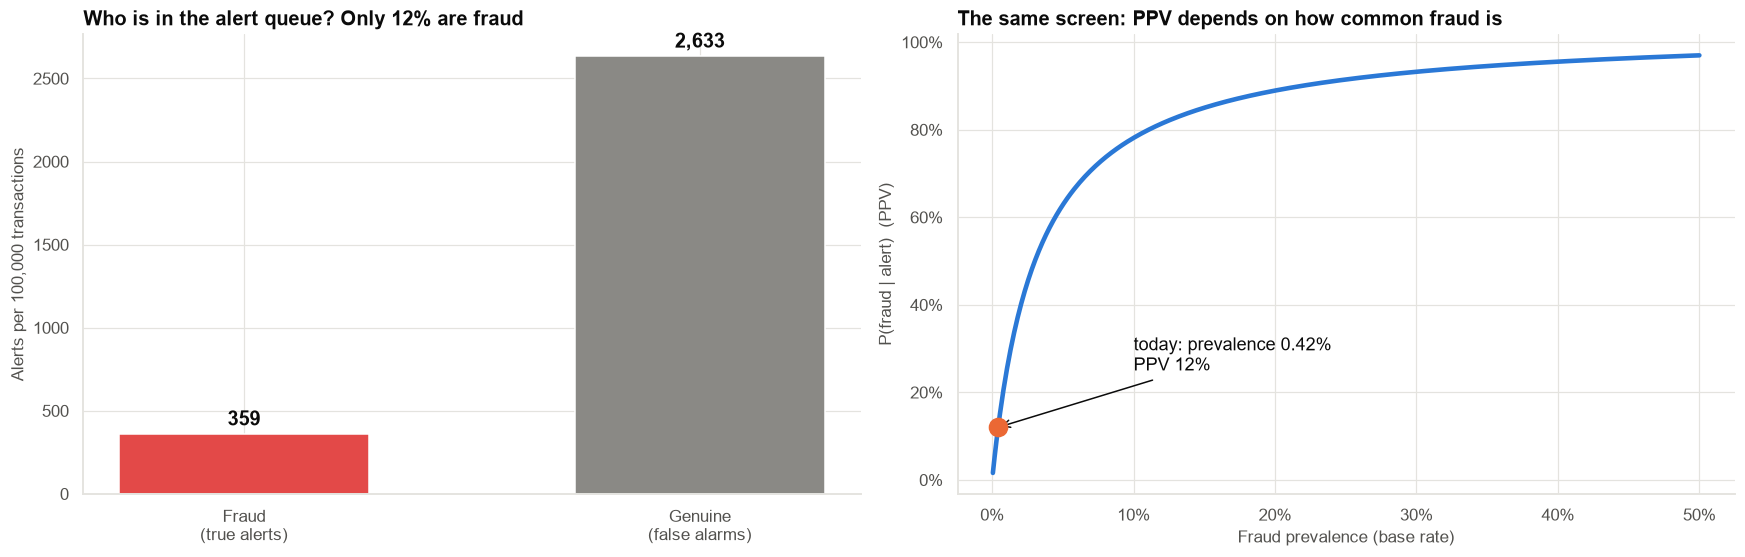

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
vals = [fraud_n * sens_r, genuine_n * (1 - spec_r)]
ax.bar(["Fraud\n(true alerts)", "Genuine\n(false alarms)"], vals, color=[COLORS["red"], INK_MUTED], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + max(vals) * 0.02, f"{v:,.0f}", ha="center", fontsize=13, fontweight="bold")
ax.set(ylabel="Alerts per 100,000 transactions", title=f"Who is in the alert queue? Only {ppv_nat:.0%} are fraud")
ax = axes[1]
pr = np.linspace(0.0005, 0.5, 400)
ppv_curve = pr * sens_r / (pr * sens_r + (1 - pr) * (1 - spec_r))
ax.plot(pr, ppv_curve, lw=3, color=PRIMARY)
ax.scatter([prev], [ppv_nat], s=140, color=HIGHLIGHT, zorder=5)
ax.annotate(f"today: prevalence {prev:.2%}\nPPV {ppv_nat:.0%}", (prev, ppv_nat), xytext=(0.1, 0.25), arrowprops=dict(arrowstyle="->", color=INK), fontsize=12)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="Fraud prevalence (base rate)", ylabel="P(fraud | alert)  (PPV)", title="The same screen: PPV depends on how common fraud is")
fig.tight_layout()
save_fig(fig, "fig01_natural_frequencies_and_ppv", PATHS["figures"])
plt.show()

**Observation.** The rule's **sensitivity is 85%** (95% CI 82% to 88%) and its specificity 97.4%, yet only **12.0%** of its
alerts are fraud (95% CI 11.1% to 13.0%). Out of 100,000 transactions about 360 alerts are true and **about 2,630 are false
alarms**. The "85%" is P(alert | fraud); the number the operations head needs is P(fraud | alert), which is a different
quantity. The PPV curve shows it depends on the base rate: at today's prevalence (0.42%) it is 12%, and it would reach 50%
only if fraud were about 3% of transactions.

**Interpretation.** This is the **prosecutor's fallacy** (base-rate neglect). A 2.6% false-alarm rate applied to the 99.6%
of genuine transactions produces far more alerts than an 85% hit rate applied to the 0.4% that are fraud.

**Implication.** Blocking on a single rule alert would stop about 360 frauds and block about 2,630 genuine customers per
100,000 transactions.

**Caveat.** The intervals treat transactions as independent and the error rates as stable over time.

## Section 6 — Bayes' theorem, in probability and in odds form

**Probability form:**

P(fraud | alert) = P(alert | fraud) · P(fraud) ÷ [ P(alert | fraud) · P(fraud) + P(alert | genuine) · P(genuine) ]

**Odds form** (easier to chain):

**posterior odds = prior odds × likelihood ratio**, where the **positive likelihood ratio** LR⁺ = sensitivity ÷ (1 − specificity)
says how many times more likely an alert is for fraud than for a genuine transaction.

In [6]:
lr_rows = []
for name, col in [("Rule engine", "alert_rule"), ("ML score", "alert_ml")]:
    tp, fp, fn, tn = confusion(col)
    sens, fpr = tp / (tp + fn), fp / (fp + tn)
    lr_pos, lr_neg = sens / fpr, (1 - sens) / (1 - fpr)
    prior_odds = prev / (1 - prev); post_odds = prior_odds * lr_pos
    lr_rows.append({"screen": name, "LR+ (alert)": lr_pos, "LR- (no alert)": lr_neg, "prior odds": prior_odds, "posterior odds after alert": post_odds,
                    "posterior probability after alert": post_odds / (1 + post_odds),
                    "posterior probability after NO alert": (prior_odds * lr_neg) / (1 + prior_odds * lr_neg)})
lr = pd.DataFrame(lr_rows).set_index("screen")
save_table(lr, "likelihood_ratios", PATHS["tables"])
lr.T

screen,Rule engine,ML score
LR+ (alert),32.1480,40.2118
LR- (no alert),0.1539,0.1884
prior odds,0.0042,0.0042
posterior odds after alert,0.1365,0.1707
posterior probability after alert,0.1201,0.1458
posterior probability after NO alert,0.0007,0.0008


**Observation.** The rule's alert multiplies the odds of fraud by about **32** (LR⁺) and the ML score's by about **40**.
Prior odds are tiny (0.0042, about 1 in 237), so after a rule alert the odds are 0.137 (about 1 in 7), a probability of 12%.
A **no-alert** divides the odds by about 6.5 (LR⁻ = 0.15) and leaves a 0.07% chance of fraud (negative predictive
value 99.93%).

**Interpretation.** A likelihood ratio of 32 is strong evidence, but strong evidence applied to very small prior odds still
gives a modest probability. The odds form makes this visible and lets us chain evidence.

## Section 7 — The base rate differs by channel

The overall prevalence hides very different risk levels. The same rule, with a **different false-alarm rate** in each
channel, has a very different PPV in each.

In [7]:
rows = []
for ch, d in tx.groupby("channel"):
    n_f = d.confirmed_fraud.sum(); n_g = len(d) - n_f
    tp = ((d.alert_rule == 1) & (d.confirmed_fraud == 1)).sum(); fp = ((d.alert_rule == 1) & (d.confirmed_fraud == 0)).sum()
    rows.append({"channel": ch, "prevalence": n_f / len(d), "sensitivity": tp / n_f, "false-alarm rate": fp / n_g, "alerts": tp + fp,
                 "PPV": tp / (tp + fp), "PPV CI low": wilson(tp, tp + fp)[0], "PPV CI high": wilson(tp, tp + fp)[1],
                 "frauds missed": n_f - tp, "share of all alerts": np.nan})
by_ch = pd.DataFrame(rows).set_index("channel")
by_ch["share of all alerts"] = by_ch["alerts"] / by_ch["alerts"].sum()
save_table(by_ch, "ppv_by_channel", PATHS["tables"])
by_ch

,prevalence,sensitivity,false-alarm rate,alerts,PPV,PPV CI low,PPV CI high,frauds missed,share of all alerts
channel,,,,,,,,,
Card not present,0.0093,0.8622,0.0398,2142,0.1695,0.1542,0.1859,58,0.4772
Card present,0.0016,0.8281,0.0198,1739,0.0610,0.0506,0.0732,22,0.3874
UPI,0.0038,0.8235,0.0240,608,0.1151,0.0921,0.1430,15,0.1354


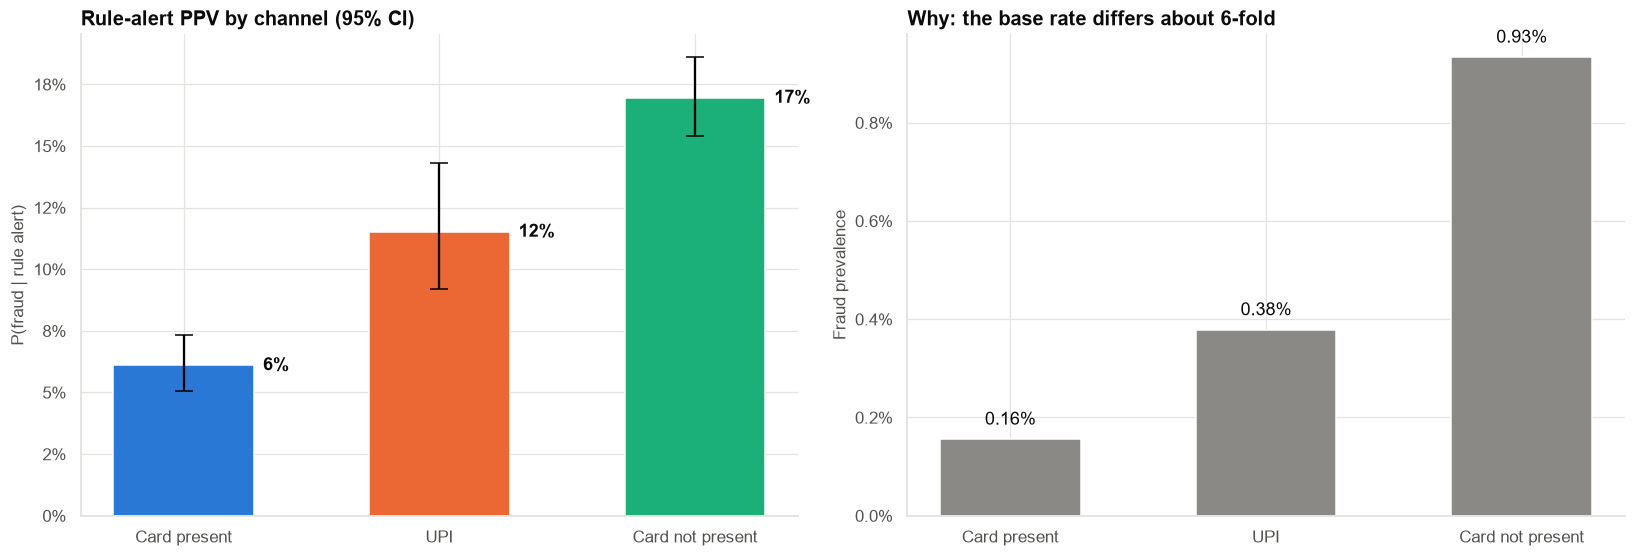

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
order = ["Card present", "UPI", "Card not present"]
b = by_ch.loc[order]
ax.bar(order, b["PPV"], color=[CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[2]], width=0.55, yerr=[b["PPV"] - b["PPV CI low"], b["PPV CI high"] - b["PPV"]], capsize=6)
for i, v in enumerate(b["PPV"]):
    ax.text(i + 0.31, v, f"{v:.0%}", va="center", fontsize=12, fontweight="bold")
ax.yaxis.set_major_formatter(pct)
ax.set(ylabel="P(fraud | rule alert)", title="Rule-alert PPV by channel (95% CI)")
ax = axes[1]
ax.bar(order, b["prevalence"], color=INK_MUTED, width=0.55)
for i, v in enumerate(b["prevalence"]):
    ax.text(i, v + 0.0003, f"{v:.2%}", ha="center", fontsize=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(ylabel="Fraud prevalence", title="Why: the base rate differs about 6-fold")
fig.tight_layout()
save_fig(fig, "fig02_ppv_by_channel", PATHS["figures"])
plt.show()

**Observation.** Fraud prevalence is 0.93% for card-not-present, 0.38% for UPI and 0.16% for card-present. Sensitivity is similar
(83% to 86%), but the rule's false-alarm rate differs (4.0%, 2.4% and 2.0%). The resulting PPV is **17.0%** (95% CI 15.4% to
18.6%) for card-not-present, **11.5%** (9.2% to 14.3%) for UPI and **6.1%** (5.1% to 7.3%) for card-present. Card-present
transactions produce 39% of all alerts at the lowest PPV.

**Interpretation.** The same rule means different things in different channels. Higher prevalence raises the PPV in
card-not-present even though that channel also has the highest false-alarm rate; the base rate is about 6 times higher, the
false-alarm rate only 2 times higher.

**Caveat.** Differences in sensitivity between channels rest on 130 to 380 frauds each and should not be over-read.

## Section 8 — A second alert: updating the odds

Both screens can fire on the same transaction. If the two are **conditionally independent given the true status**, their
likelihood ratios multiply: posterior odds = prior odds × LR_rule × LR_ml. We compute this prediction and check it
against the data.

In [9]:
tp_m = ((tx.alert_ml == 1) & (tx.confirmed_fraud == 1)).sum(); fn_m = ((tx.alert_ml == 0) & (tx.confirmed_fraud == 1)).sum()
fp_m = ((tx.alert_ml == 1) & (tx.confirmed_fraud == 0)).sum(); tn_m = ((tx.alert_ml == 0) & (tx.confirmed_fraud == 0)).sum()
lr_ml, lr_ml_neg = (tp_m / (tp_m + fn_m)) / (fp_m / (fp_m + tn_m)), (fn_m / (tp_m + fn_m)) / (tn_m / (fp_m + tn_m))
lr_rule, lr_rule_neg = lr.loc["Rule engine", "LR+ (alert)"], lr.loc["Rule engine", "LR- (no alert)"]
prior_o = prev / (1 - prev)
tx["pattern"] = np.select([(tx.alert_rule == 1) & (tx.alert_ml == 1), (tx.alert_rule == 1), (tx.alert_ml == 1)], ["both alert", "rule only", "ML only"], "neither")
pred_o = {"both alert": prior_o * lr_rule * lr_ml, "rule only": prior_o * lr_rule * lr_ml_neg, "ML only": prior_o * lr_rule_neg * lr_ml, "neither": prior_o * lr_rule_neg * lr_ml_neg}
rows = []
for pat in ["neither", "rule only", "ML only", "both alert"]:
    d = tx[tx.pattern == pat]; k = d.confirmed_fraud.sum()
    lo, hi = wilson(k, len(d)); po = pred_o[pat]
    rows.append({"pattern": pat, "transactions": len(d), "frauds": k, "observed P(fraud)": k / len(d), "CI low": lo, "CI high": hi,
                 "Bayes prediction (independence)": po / (1 + po), "prediction inside CI?": lo <= po / (1 + po) <= hi})
pat_tbl = pd.DataFrame(rows).set_index("pattern")
save_table(pat_tbl, "alert_patterns", PATHS["tables"])
pat_tbl

,transactions,frauds,observed P(fraud),CI low,CI high,Bayes prediction (independence),prediction inside CI?
pattern,,,,,,,
neither,142474,19,0.0001,0.0001,0.0002,0.0001,True
rule only,3980,98,0.0246,0.0202,0.0299,0.0251,True
ML only,3037,76,0.0250,0.0200,0.0312,0.0256,True
both alert,509,441,0.8664,0.8341,0.8932,0.8458,True


In [10]:
# Is independence plausible? Compare the two alerts' association within the true classes.
chk = []
for lab, d in [("fraud", tx[tx.confirmed_fraud == 1]), ("genuine", tx[tx.confirmed_fraud == 0])]:
    ct = pd.crosstab(d.alert_rule, d.alert_ml)
    chi = stats.chi2_contingency(ct, correction=False)
    chk.append({"true status": lab, "n": len(d), "P(ML alert | rule alert)": ct.loc[1, 1] / ct.loc[1].sum(), "P(ML alert | no rule alert)": ct.loc[0, 1] / ct.loc[0].sum(), "chi-square p-value": chi.pvalue})
indep = pd.DataFrame(chk).set_index("true status")
save_table(indep, "independence_check", PATHS["tables"])
display(indep)
# Overall (ignoring true status) the alerts ARE associated, because both fire more for fraud:
ct_all = pd.crosstab(tx.alert_rule, tx.alert_ml)
print(f"Ignoring true status: P(ML alert | rule alert) = {ct_all.loc[1, 1] / ct_all.loc[1].sum():.1%} vs P(ML alert | no rule alert) = {ct_all.loc[0, 1] / ct_all.loc[0].sum():.1%}")

,n,P(ML alert | rule alert),P(ML alert | no rule alert),chi-square p-value
true status,,,,
fraud,634,0.8182,0.8000,0.6736
genuine,149366,0.0172,0.0204,0.1662


Ignoring true status: P(ML alert | rule alert) = 11.3% vs P(ML alert | no rule alert) = 2.1%


In [11]:
# What if the screens were positively correlated given fraud status (e.g. both react to the same signal)? Illustrate the damage:
# the product of LRs overstates the evidence when the alerts are partly redundant. Show P(fraud | both) as the joint LR is shrunk.
shrink = np.linspace(1.0, 0.4, 7)
rows = []
for s in shrink:
    lr_joint = (lr_rule * lr_ml) ** s
    po = prior_o * lr_joint
    rows.append({"share of the evidence that is independent": s, "joint LR": lr_joint, "P(fraud | both alert)": po / (1 + po)})
red = pd.DataFrame(rows).set_index("share of the evidence that is independent")
save_table(red, "redundancy_sensitivity", PATHS["tables"])
red

,joint LR,P(fraud | both alert)
share of the evidence that is independent,,
1.0000,"1,292.7303",0.8458
0.9000,631.4764,0.7283
0.8000,308.4653,0.5670
0.7000,150.6800,0.3901
0.6000,73.6046,0.2381
0.5000,35.9546,0.1324
0.4000,17.5632,0.0694


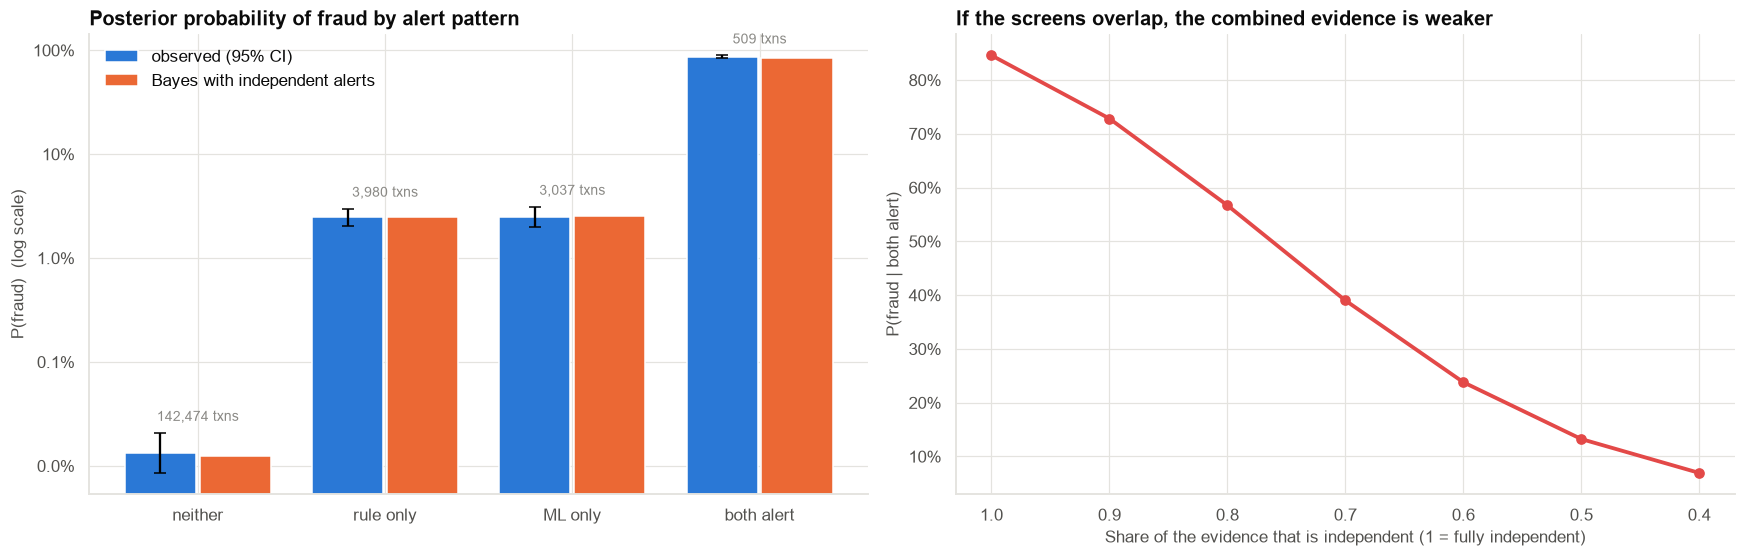

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
ordr = ["neither", "rule only", "ML only", "both alert"]
x = np.arange(4)
ax.bar(x - 0.2, pat_tbl.loc[ordr, "observed P(fraud)"], width=0.38, color=PRIMARY, label="observed (95% CI)",
       yerr=[pat_tbl.loc[ordr, "observed P(fraud)"] - pat_tbl.loc[ordr, "CI low"], pat_tbl.loc[ordr, "CI high"] - pat_tbl.loc[ordr, "observed P(fraud)"]], capsize=4)
ax.bar(x + 0.2, pat_tbl.loc[ordr, "Bayes prediction (independence)"], width=0.38, color=COLORS["orange"], label="Bayes with independent alerts")
ax.set_yscale("log"); ax.set_xticks(x, ordr)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}" if v < 0.1 else f"{v:.0%}"))
ax.set(ylabel="P(fraud)  (log scale)", title="Posterior probability of fraud by alert pattern"); ax.legend(frameon=False, loc="upper left")
for i, o in enumerate(ordr):
    ax.text(i, pat_tbl.loc[o, "CI high"] * 1.3, f"{pat_tbl.loc[o, 'transactions']:,} txns", ha="center", fontsize=9, color=INK_MUTED)
ax = axes[1]
ax.plot(red.index, red["P(fraud | both alert)"], "o-", lw=2.5, color=COLORS["red"])
ax.invert_xaxis(); ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="Share of the evidence that is independent (1 = fully independent)", ylabel="P(fraud | both alert)", title="If the screens overlap, the combined evidence is weaker")
fig.tight_layout()
save_fig(fig, "fig03_two_alerts", PATHS["figures"])
plt.show()

**Observation.** The observed fraud rates by alert pattern are 0.013% (neither; 19 of 142,474), **2.5%** (rule only; 98 of 3,980),
**2.5%** (ML only; 76 of 3,037) and **86.6%** (both; 441 of 509, CI 83.4% to 89.3%). The predictions from multiplying likelihood
ratios (0.01%, 2.51%, 2.56% and 84.6%) all fall inside the intervals. Within the true classes the two alerts show no association
(p = 0.67 among frauds, 0.17 among genuine transactions). Overall an ML alert is 11.3% likely after a rule alert versus 2.1%
otherwise, but only because both screens react to fraud.

**Interpretation.** When two screens are conditionally independent, evidence multiplies: both alerting raises the odds about
1,300-fold and makes fraud very likely (87%). If part of the evidence were shared, the combined probability would be much lower
(about 39% if only 70% of the evidence were independent; 13% at 50%).

**Caveat.** With 634 frauds the independence check has limited power, and real screens usually share signals; test it on your
own data before chaining likelihood ratios.

## Section 9 — From probability to decision: investigate or block?

An investigation costs a fixed amount; a missed fraud costs the loss. Investigate whenever
**P(fraud) × loss > cost of investigating**, i.e. when P(fraud) exceeds the **threshold p\* = cost ÷ loss** (assuming an
investigation always uncovers fraud). Blocking a genuine customer has its own cost (complaint, lost spend, attrition), so
**blocking without investigation** needs a much higher probability.

Assumptions (all stated for Finance to change): investigation ₹300; average fraud loss if not stopped ₹12,000; cost of
blocking a genuine customer ₹1,500.

In [13]:
INVEST, LOSS, BLOCK_GENUINE = 300, 12_000, 1_500
p_invest = INVEST / LOSS
p_block = BLOCK_GENUINE / (LOSS + BLOCK_GENUINE)   # block when p*LOSS > (1-p)*BLOCK_GENUINE
print(f"Investigate when P(fraud) > {p_invest:.1%}.   Block outright (no investigation) when P(fraud) > {p_block:.1%}.")
tx["segment"] = tx["channel"] + " | " + tx["pattern"]
seg = tx.groupby("segment").agg(transactions=("txn_id", "size"), frauds=("confirmed_fraud", "sum"))
seg["P(fraud)"] = seg.frauds / seg.transactions
seg["CI low"] = [wilson(k, n)[0] for k, n in zip(seg.frauds, seg.transactions)]
seg["CI high"] = [wilson(k, n)[1] for k, n in zip(seg.frauds, seg.transactions)]
seg["decision"] = np.select([seg["P(fraud)"] > p_block, seg["P(fraud)"] > p_invest], ["block", "investigate"], "pass")
seg["expected cost per txn, pass (₹)"] = seg["P(fraud)"] * LOSS
seg["expected cost per txn, investigate (₹)"] = INVEST + 0 * seg["P(fraud)"]
seg = seg.sort_values("P(fraud)", ascending=False)
save_table(seg, "decision_by_segment", PATHS["tables"])
seg

Investigate when P(fraud) > 2.5%.   Block outright (no investigation) when P(fraud) > 11.1%.


,transactions,frauds,P(fraud),CI low,CI high,decision,"expected cost per txn, pass (₹)","expected cost per txn, investigate (₹)"
segment,,,,,,,,
Card not present | both alert,328,297,0.9055,0.8690,0.9326,block,"10,865.8537",300.0000
UPI | both alert,68,58,0.8529,0.7500,0.9181,block,"10,235.2941",300.0000
Card present | both alert,113,86,0.7611,0.6747,0.8303,block,"9,132.7434",300.0000
Card not present | ML only,958,48,0.0501,0.0380,0.0658,investigate,601.2526,300.0000
Card not present | rule only,1814,66,0.0364,0.0287,0.0460,investigate,436.6042,300.0000
UPI | ML only,472,11,0.0233,0.0131,0.0412,pass,279.6610,300.0000
UPI | rule only,540,12,0.0222,0.0128,0.0384,pass,266.6667,300.0000
Card present | rule only,1626,20,0.0123,0.0080,0.0189,pass,147.6015,300.0000
Card present | ML only,1607,17,0.0106,0.0066,0.0169,pass,126.9446,300.0000


In [14]:
policies = {}
tx_ = tx.merge(seg[["P(fraud)"]].rename(columns={"P(fraud)": "p_seg"}), left_on="segment", right_index=True)
def cost(action):
    # action: 'pass', 'investigate', 'block' per transaction
    c = np.where(action == "pass", tx_.confirmed_fraud * LOSS, np.where(action == "investigate", INVEST, tx_.confirmed_fraud * 0 + (1 - tx_.confirmed_fraud) * BLOCK_GENUINE + INVEST * 0))
    return c.sum()
pol = {
    "Pass everything (no screening)": np.array(["pass"] * len(tx_)),
    "Block every rule alert (the operations head's plan)": np.where(tx_.alert_rule == 1, "block", "pass"),
    "Investigate every rule alert": np.where(tx_.alert_rule == 1, "investigate", "pass"),
    "Probability-based (investigate above p*, block above block threshold)": np.where(tx_.p_seg > p_block, "block", np.where(tx_.p_seg > p_invest, "investigate", "pass")),
}
rows = []
for k, a in pol.items():
    flagged = a != "pass"
    rows.append({"policy": k, "total cost (₹ lakh)": cost(a) / 1e5, "transactions touched": flagged.sum(), "frauds stopped": int(((tx_.confirmed_fraud == 1) & flagged).sum()),
                 "genuine customers blocked": int(((tx_.confirmed_fraud == 0) & (a == "block")).sum())})
pol_tbl = pd.DataFrame(rows).set_index("policy")
save_table(pol_tbl, "policy_costs", PATHS["tables"])
pol_tbl

,total cost (₹ lakh),transactions touched,frauds stopped,genuine customers blocked
policy,,,,
Pass everything (no screening),76.0800,0,0,0
Block every rule alert (the operations head's plan),70.6500,4489,539,3950
Investigate every rule alert,24.8670,4489,539,0
"Probability-based (investigate above p*, block above block threshold)",18.8160,3281,555,68


**Observation.** The thresholds are **investigate above 2.5%** (₹300 ÷ ₹12,000) and **block outright above 11.1%**. Transactions where
both screens alert have a fraud probability of 76% to 91% in every channel: block. Card-not-present transactions with one alert
(3.6% to 5.0%) clear the investigation threshold. UPI single alerts (2.2% to 2.3%) sit just under it, with intervals that straddle
it (1.3% to 4.1%). Card-present single alerts (1.1% to 1.2%) and no-alert transactions (0.01% to 0.02%) pass.

On total cost: passing everything costs **₹76.1 lakh**; **blocking every rule alert costs ₹70.7 lakh** (and blocks 3,950 genuine
customers); investigating every rule alert costs ₹24.9 lakh; the probability-based policy costs **₹18.8 lakh**, touches 3,281
transactions, stops 555 frauds and blocks 68 genuine customers.

**Interpretation.** Blocking on the rule alone barely beats doing nothing, because the cost of blocking 3,950 genuine customers
nearly cancels the fraud prevented. Investigating is much cheaper than blocking, and combining the evidence beats both.

**Caveats.** The policy thresholds were applied to the same data used to estimate segment probabilities, so its advantage is
somewhat optimistic; costs are assumptions; borderline segments (UPI single alerts) should be decided with cost-of-error in mind.

## Section 10 — Small groups: Beta-Binomial rates and shrinkage

The merchant-group table shows frauds out of a few hundred or a few thousand transactions. A raw rate such as
"3 frauds in 189 transactions = 1.6%" is very noisy. The **Beta-Binomial** model gives a principled estimate:

- **Prior:** the rate p ~ Beta(a, b) (what we believe before seeing the group's data).
- **Data:** k frauds in n transactions ~ Binomial(n, p).
- **Posterior:** p | data ~ Beta(a + k, b + n − k): the prior counts are simply added to the observed counts.

The posterior mean is a **weighted average of the raw rate and the prior mean**, with weight n ÷ (n + a + b) on the data.
Groups with little data are pulled further toward the overall rate: **shrinkage**.

We estimate the prior from the data across all groups (**empirical Bayes**, by maximum likelihood of the Beta-Binomial).

In [15]:
from scipy.special import betaln, gammaln
from scipy.optimize import minimize

def nll(par):
    a, b = np.exp(par)
    ll = gammaln(mg.transactions + 1) - gammaln(mg.frauds + 1) - gammaln(mg.transactions - mg.frauds + 1) + betaln(mg.frauds + a, mg.transactions - mg.frauds + b) - betaln(a, b)
    return -ll.sum()
fit = minimize(nll, x0=np.log([1.0, 200.0]), method="Nelder-Mead")
a0, b0 = np.exp(fit.x)
print(f"Empirical-Bayes prior: Beta({a0:.2f}, {b0:.0f});  prior mean {a0 / (a0 + b0):.3%};  prior 'sample size' a + b = {a0 + b0:.0f} transactions")
pooled = mg.frauds.sum() / mg.transactions.sum()
mg["raw rate"] = mg.frauds / mg.transactions
mg["raw CI low"] = [wilson(k, n)[0] for k, n in zip(mg.frauds, mg.transactions)]
mg["raw CI high"] = [wilson(k, n)[1] for k, n in zip(mg.frauds, mg.transactions)]
mg["posterior mean"] = (a0 + mg.frauds) / (a0 + b0 + mg.transactions)
mg["post CI low"] = stats.beta.ppf(0.025, a0 + mg.frauds, b0 + mg.transactions - mg.frauds)
mg["post CI high"] = stats.beta.ppf(0.975, a0 + mg.frauds, b0 + mg.transactions - mg.frauds)
mg["weight on own data"] = mg.transactions / (mg.transactions + a0 + b0)
THRESH = 0.01
mg["P(rate > 1%)"] = 1 - stats.beta.cdf(THRESH, a0 + mg.frauds, b0 + mg.transactions - mg.frauds)
mg["raw rank"] = mg["raw rate"].rank(ascending=False).astype(int)
mg["posterior rank"] = mg["posterior mean"].rank(ascending=False).astype(int)
save_table(mg.set_index("group"), "merchant_group_estimates", PATHS["tables"])
mg.set_index("group")[["transactions", "frauds", "raw rate", "raw CI low", "raw CI high", "posterior mean", "post CI low", "post CI high", "weight on own data", "P(rate > 1%)", "raw rank", "posterior rank"]]

Empirical-Bayes prior: Beta(4.35, 740);  prior mean 0.585%;  prior 'sample size' a + b = 744 transactions


,transactions,frauds,raw rate,raw CI low,raw CI high,posterior mean,post CI low,post CI high,weight on own data,P(rate > 1%),raw rank,posterior rank
group,,,,,,,,,,,,
Merchant group A,2482,6,0.0024,0.0011,0.0053,0.0032,0.0016,0.0054,0.7693,0.0000,13,13
Merchant group B,1579,6,0.0038,0.0017,0.0083,0.0045,0.0022,0.0075,0.6796,0.0009,9,9
Merchant group C,417,3,0.0072,0.0024,0.0209,0.0063,0.0026,0.0116,0.3591,0.0716,5,5
Merchant group D,600,4,0.0067,0.0026,0.0170,0.0062,0.0027,0.0111,0.4463,0.0537,6,6
Merchant group E,1481,8,0.0054,0.0027,0.0106,0.0056,0.0029,0.0090,0.6655,0.0084,7,7
Merchant group F,705,2,0.0028,0.0008,0.0103,0.0044,0.0017,0.0084,0.4864,0.0056,11,10
Merchant group G,189,3,0.0159,0.0054,0.0456,0.0079,0.0033,0.0145,0.2025,0.2131,1,3
Merchant group H,2268,5,0.0022,0.0009,0.0052,0.0031,0.0014,0.0054,0.7529,0.0000,14,14
Merchant group I,2035,15,0.0074,0.0045,0.0121,0.0070,0.0042,0.0104,0.7322,0.0380,4,4


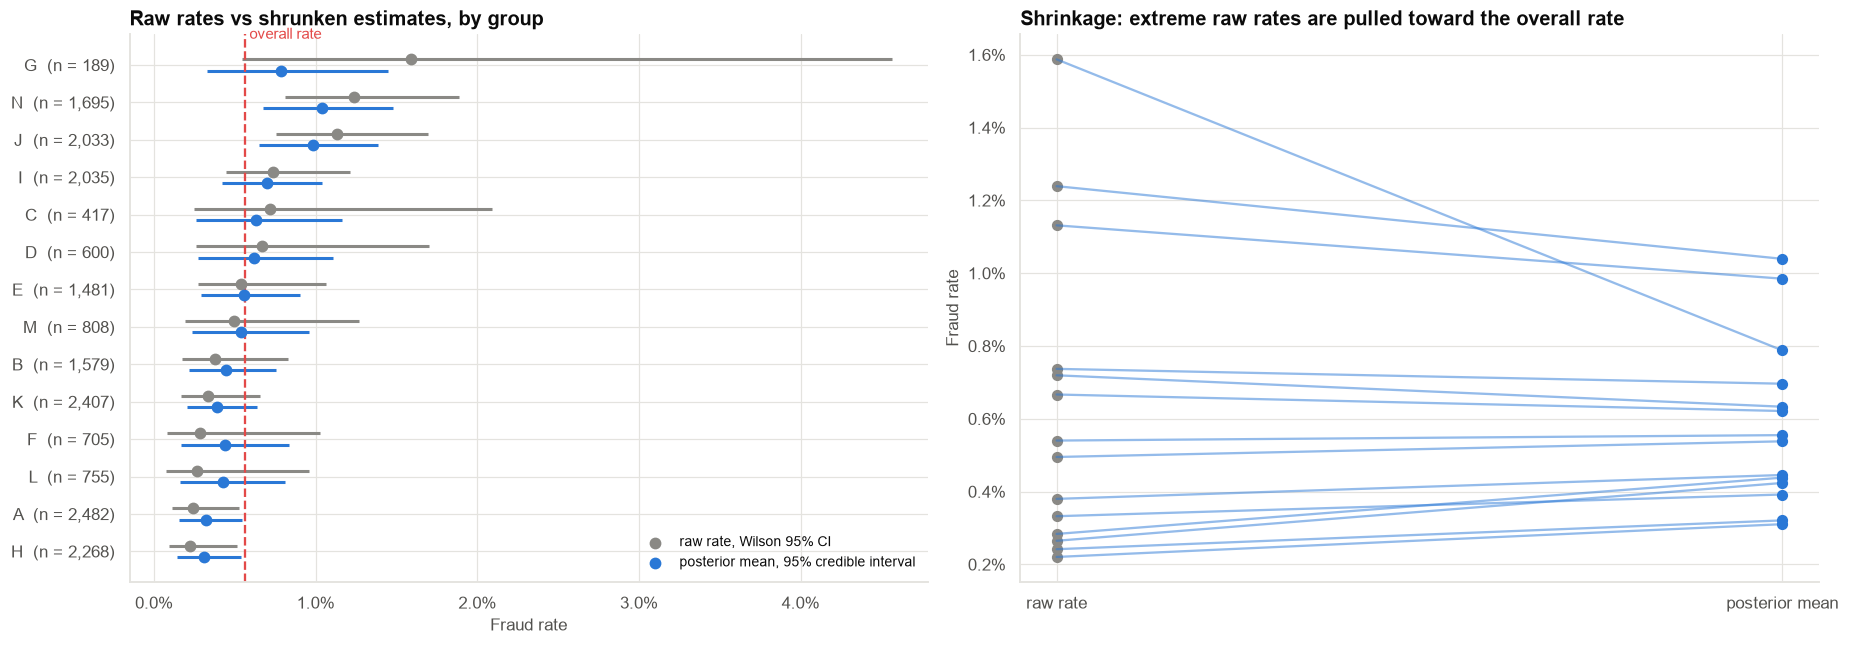

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ax = axes[0]
srt = mg.sort_values("raw rate")
y = np.arange(len(srt))
ax.hlines(y + 0.15, srt["raw CI low"], srt["raw CI high"], color=INK_MUTED, lw=2)
ax.scatter(srt["raw rate"], y + 0.15, color=INK_MUTED, s=45, label="raw rate, Wilson 95% CI", zorder=3)
ax.hlines(y - 0.15, srt["post CI low"], srt["post CI high"], color=PRIMARY, lw=2)
ax.scatter(srt["posterior mean"], y - 0.15, color=PRIMARY, s=45, label="posterior mean, 95% credible interval", zorder=3)
ax.axvline(pooled, color=COLORS["red"], ls="--", lw=1.5); ax.text(pooled, len(srt) - 0.3, " overall rate", color=COLORS["red"], fontsize=10)
ax.set_yticks(y, [f"{g.replace('Merchant group ', '')}  (n = {n:,})" for g, n in zip(srt.group, srt.transactions)])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(xlabel="Fraud rate", title="Raw rates vs shrunken estimates, by group"); ax.legend(frameon=False, loc="lower right", fontsize=9)
ax = axes[1]
for _, r_ in mg.iterrows():
    ax.plot([0, 1], [r_["raw rate"], r_["posterior mean"]], color=COLORS["blue"], alpha=0.5, lw=1.5)
ax.scatter(np.zeros(len(mg)), mg["raw rate"], color=INK_MUTED, s=40); ax.scatter(np.ones(len(mg)), mg["posterior mean"], color=PRIMARY, s=40)
ax.set_xticks([0, 1], ["raw rate", "posterior mean"]); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(ylabel="Fraud rate", title="Shrinkage: extreme raw rates are pulled toward the overall rate")
fig.tight_layout()
save_fig(fig, "fig04_beta_binomial_shrinkage", PATHS["figures"])
plt.show()

**Observation.** The empirical-Bayes prior is Beta(4.4, 740): mean 0.59%, worth about 744 transactions. Small groups are pulled
furthest: group G (3 frauds in 189 transactions) moves from a raw 1.59% to 0.79% (weight 20% on its own data), and group C
(417 transactions) from 0.72% to 0.63%. Large groups such as A, H and K (about 2,300 to 2,500 transactions) move little. G's
raw 95% interval is 0.5% to 4.6%; its credible interval is 0.33% to 1.45%. Group G's rank falls from 1 to 3.

**Interpretation.** Raw league tables reward luck in small groups. The posterior mean is a weighted average of the raw rate and
the overall rate, with more weight on the data when the group has more transactions.

### 10.1 How much does the prior matter? Posterior for one small group

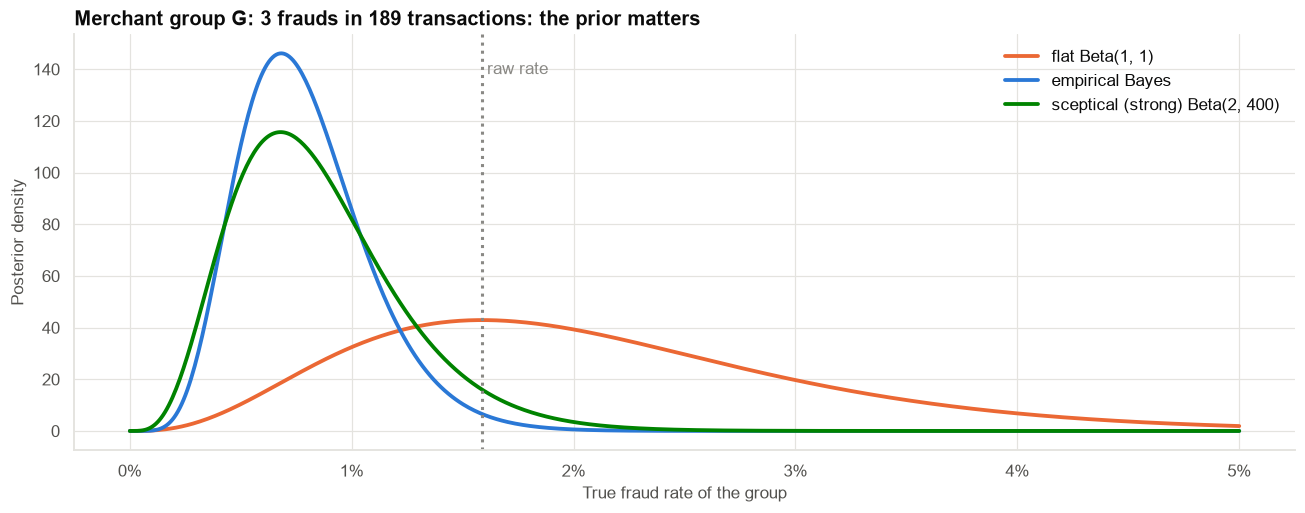

,posterior mean,95% credible low,95% credible high,P(rate > 1%)
prior,,,,
"flat Beta(1, 1)",0.0209,0.0058,0.0454,0.8757
empirical Bayes,0.0079,0.0033,0.0145,0.2131
"sceptical (strong) Beta(2, 400)",0.0085,0.0028,0.0173,0.2973


In [17]:
g = mg.loc[mg.transactions.idxmin()]
priors = {"flat Beta(1, 1)": (1, 1), "empirical Bayes": (a0, b0), "sceptical (strong) Beta(2, 400)": (2, 400)}
xs = np.linspace(0, 0.05, 600)
rows = []
fig, ax = plt.subplots(figsize=(12, 4.8))
for (lab, (a, b)), c in zip(priors.items(), [COLORS["orange"], PRIMARY, COLORS["green"]]):
    post = stats.beta(a + g.frauds, b + g.transactions - g.frauds)
    ax.plot(xs, post.pdf(xs), lw=2.5, color=c, label=lab)
    rows.append({"prior": lab, "posterior mean": post.mean(), "95% credible low": post.ppf(0.025), "95% credible high": post.ppf(0.975), "P(rate > 1%)": 1 - post.cdf(0.01)})
ax.axvline(g["raw rate"], color=INK_MUTED, ls=":", lw=2); ax.text(g["raw rate"], ax.get_ylim()[1] * 0.9, " raw rate", color=INK_MUTED)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="True fraud rate of the group", ylabel="Posterior density", title=f"{g.group}: {int(g.frauds)} frauds in {int(g.transactions)} transactions: the prior matters"); ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig05_prior_sensitivity", PATHS["figures"])
plt.show()
prior_tbl = pd.DataFrame(rows).set_index("prior")
save_table(prior_tbl, "prior_sensitivity", PATHS["tables"])
prior_tbl

**Observation.** For group G (3 frauds in 189 transactions) a flat Beta(1, 1) prior gives a posterior mean of 2.1% and an
88% probability that the rate exceeds 1%; the empirical-Bayes prior gives 0.79% and 21%; a strong sceptical Beta(2, 400) prior
gives 0.85% and 30%.

**Interpretation.** With little data the prior matters a great deal. A flat prior is not neutral: it treats a 20% fraud rate as
plausible as 0.5%. Fit the prior from other groups, or state it and show a sensitivity analysis.

## Section 11 — Which groups are really worse than average?

With 14 groups some will look bad by chance. We rank by the **posterior probability that the rate exceeds 1%**, and compare
the raw "top 3" with the posterior "top 3".

In [18]:
top_raw = mg.nlargest(3, "raw rate")["group"].tolist(); top_post = mg.nlargest(3, "P(rate > 1%)")["group"].tolist()
print("Top 3 by RAW rate:         ", top_raw)
print("Top 3 by P(rate > 1%):     ", top_post)
mg[["group", "transactions", "frauds", "raw rate", "P(rate > 1%)"]].sort_values("P(rate > 1%)", ascending=False).set_index("group")

Top 3 by RAW rate:          ['Merchant group G', 'Merchant group N', 'Merchant group J']
Top 3 by P(rate > 1%):      ['Merchant group N', 'Merchant group J', 'Merchant group G']


,transactions,frauds,raw rate,P(rate > 1%)
group,,,,
Merchant group N,1695,21,0.0124,0.5511
Merchant group J,2033,23,0.0113,0.4431
Merchant group G,189,3,0.0159,0.2131
Merchant group C,417,3,0.0072,0.0716
Merchant group D,600,4,0.0067,0.0537
Merchant group I,2035,15,0.0074,0.0380
Merchant group M,808,4,0.0050,0.0173
Merchant group E,1481,8,0.0054,0.0084
Merchant group F,705,2,0.0028,0.0056


**Observation.** The groups most likely to exceed a 1% fraud rate are **N** (55% probability) and **J** (44%); G is third (21%)
although its raw rate is highest. The raw and posterior-probability top 3 contain the same groups in different order. Even the
top group is only about 55% likely to be above 1%.

**Interpretation.** A probability of exceeding the threshold communicates the uncertainty that a raw ranking hides; no group is
beyond reasonable doubt.

## Section 12 — Results

In [19]:
ppvr = perf.loc["Rule engine", "PPV P(fraud|alert)"]
summary = pd.DataFrame({"Value": [
    f"rule sensitivity {perf.loc['Rule engine', 'sensitivity P(alert|fraud)']:.0%}, specificity {perf.loc['Rule engine', 'specificity P(no alert|genuine)']:.1%}, prevalence {prev:.2%}",
    f"P(fraud | rule alert) = {ppvr:.1%} (95% CI {perf.loc['Rule engine', 'PPV CI low']:.1%} to {perf.loc['Rule engine', 'PPV CI high']:.1%}); {1 - ppvr:.0%} of alerts are false alarms",
    f"PPV by channel: " + ", ".join(f"{c} {by_ch.loc[c, 'PPV']:.0%}" for c in ["Card present", "UPI", "Card not present"]),
    f"LR+ rule {lr.loc['Rule engine', 'LR+ (alert)']:.0f}, ML {lr.loc['ML score', 'LR+ (alert)']:.0f}; P(fraud | both alert) observed {pat_tbl.loc['both alert', 'observed P(fraud)']:.0%} vs independent-Bayes prediction {pat_tbl.loc['both alert', 'Bayes prediction (independence)']:.0%}",
    f"investigate above {p_invest:.1%}; block above {p_block:.0%}; cheapest policy: {pol_tbl['total cost (₹ lakh)'].idxmin()}",
    f"merchant groups: empirical-Bayes prior Beta({a0:.1f}, {b0:.0f}); top 3 by raw rate {top_raw}, by P(rate>1%) {top_post}",
]}, index=["Rule engine", "Alert meaning", "Base rate", "Two alerts", "Decision", "Small groups"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Rule engine,"rule sensitivity 85%, specificity 97.4%, preva..."
Alert meaning,P(fraud | rule alert) = 12.0% (95% CI 11.1% to...
Base rate,"PPV by channel: Card present 6%, UPI 12%, Card..."
Two alerts,"LR+ rule 32, ML 40; P(fraud | both alert) obse..."
Decision,investigate above 2.5%; block above 11%; cheap...
Small groups,merchant groups: empirical-Bayes prior Beta(4....


## Section 13 — Grading the shrinkage estimates (using the answer key)

In [20]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv").set_index("group")["true_fraud_rate"]
cmp_ = mg.set_index("group")[["raw rate", "posterior mean", "post CI low", "post CI high", "raw CI low", "raw CI high", "transactions"]].join(key)
cmp_["raw error"] = cmp_["raw rate"] - cmp_["true_fraud_rate"]; cmp_["posterior error"] = cmp_["posterior mean"] - cmp_["true_fraud_rate"]
grade = pd.DataFrame({"mean squared error (×10⁻⁶)": [1e6 * (cmp_["raw error"] ** 2).mean(), 1e6 * (cmp_["posterior error"] ** 2).mean()],
                      "mean absolute error (pp)": [100 * cmp_["raw error"].abs().mean(), 100 * cmp_["posterior error"].abs().mean()],
                      "95% intervals covering the truth": [((cmp_["raw CI low"] <= cmp_.true_fraud_rate) & (cmp_.true_fraud_rate <= cmp_["raw CI high"])).sum(),
                                                            ((cmp_["post CI low"] <= cmp_.true_fraud_rate) & (cmp_.true_fraud_rate <= cmp_["post CI high"])).sum()],
                      "mean interval width (pp)": [100 * (cmp_["raw CI high"] - cmp_["raw CI low"]).mean(), 100 * (cmp_["post CI high"] - cmp_["post CI low"]).mean()]},
                     index=["raw rates (Wilson CI)", "Beta-Binomial posterior"])
save_table(grade, "shrinkage_grading", PATHS["tables"])
display(grade)
top_true = key.nlargest(3).index.tolist()
print("True top 3 groups:", top_true, "| raw top 3 hits:", len(set(top_true) & set(top_raw)), "| posterior-probability top 3 hits:", len(set(top_true) & set(top_post)))
# A single set of 14 groups is a small test: repeat on many fresh draws.
R = 3000; mse_raw = []; mse_post = []
for _ in range(R):
    tr = rng.beta(2, 400, 14); sz = rng.integers(150, 2500, 14); fr = rng.binomial(sz, tr)
    a_, b_ = a0, b0
    mse_raw.append(((fr / sz - tr) ** 2).mean()); mse_post.append((((a_ + fr) / (a_ + b_ + sz) - tr) ** 2).mean())
print(f"Repeated on {R:,} fresh sets of 14 groups: mean squared error raw {1e6 * np.mean(mse_raw):.2f}e-6 vs posterior {1e6 * np.mean(mse_post):.2f}e-6; posterior better in {np.mean(np.array(mse_post) < np.array(mse_raw)):.0%} of sets")
cmp_[["transactions", "raw rate", "posterior mean", "true_fraud_rate", "raw error", "posterior error"]]

,mean squared error (×10⁻⁶),mean absolute error (pp),95% intervals covering the truth,mean interval width (pp)
raw rates (Wilson CI),3.1498,0.1500,14,1.1260
Beta-Binomial posterior,5.6478,0.2040,12,0.6719


True top 3 groups: ['Merchant group G', 'Merchant group N', 'Merchant group I'] | raw top 3 hits: 2 | posterior-probability top 3 hits: 2


Repeated on 3,000 fresh sets of 14 groups: mean squared error raw 5.93e-6 vs posterior 3.93e-6; posterior better in 71% of sets


,transactions,raw rate,posterior mean,true_fraud_rate,raw error,posterior error
group,,,,,,
Merchant group A,2482,0.0024,0.0032,0.0047,-0.0023,-0.0015
Merchant group B,1579,0.0038,0.0045,0.0022,0.0016,0.0023
Merchant group C,417,0.0072,0.0063,0.0075,-0.0003,-0.0012
Merchant group D,600,0.0067,0.0062,0.0043,0.0024,0.0020
Merchant group E,1481,0.0054,0.0056,0.0045,0.0009,0.0010
Merchant group F,705,0.0028,0.0044,0.0016,0.0013,0.0028
Merchant group G,189,0.0159,0.0079,0.0133,0.0026,-0.0054
Merchant group H,2268,0.0022,0.0031,0.0027,-0.0005,0.0004
Merchant group I,2035,0.0074,0.0070,0.0091,-0.0018,-0.0022


**Observation.** In this one set of 14 groups the shrinkage estimates did **not** beat the raw rates: mean squared error 5.6 × 10⁻⁶ against
3.1 × 10⁻⁶, and mean absolute error 0.20 against 0.15 points. The Wilson intervals covered all 14 true rates (mean width 1.13
points); the credible intervals covered 12 of 14 and were narrower (0.67 points). The true top 3 are G, N and I; both
approaches found 2 of the 3. Over **3,000 fresh sets** of 14 groups the posterior has the lower squared error (3.9 × 10⁻⁶ against
5.9 × 10⁻⁶) and is better in 71% of sets, but not in all of them.

**Interpretation.** Shrinkage is better **on average**, not in every dataset. In this draw the estimated prior (mean 0.59%) was
somewhat above the true mean (0.50%), which pulled low-risk groups upward. One small set of groups cannot judge calibration.

**Caveat.** The repeat simulation reuses the prior fitted to this dataset and ignores uncertainty in the prior itself.

## Section 14 — Interpretation

- **Sensitivity is not predictive value.** What matters when an alert fires is P(fraud | alert), which depends on the **base
  rate** as much as on the screen.
- **Odds make updating easy**: prior odds × likelihood ratio. Chain likelihood ratios only if the screens are
  conditionally independent.
- **Decisions need costs**, not just probabilities: the investigation threshold is cost ÷ loss.
- **Small groups need shrinkage**: raw rates over-react to noise; Beta-Binomial estimates borrow strength from the other
  groups, trading a little bias for a lot less variance.

## Section 15 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "When the rule fires, about 1 in 8 alerts is fraud; the rest are false alarms." | "The rule catches 85% of fraud, so an alert means fraud." |
| "Card-not-present alerts are far more likely to be fraud than card-present alerts, because the base rate is higher." | "The rule performs better on card-not-present transactions" (sensitivity is the same; the base rate differs). |
| "Both alerts firing makes fraud very likely; the observed rate matches the independence-based prediction." | "Two alerts are always twice as good" (only if independent). |
| "Group N's fraud rate is probably above 1%; group G's raw rate is mostly noise." | "Group G is the riskiest merchant group" (3 frauds in 189 transactions). |

## Section 16 — Business interpretation

- **Do not block on a single alert.** Investigate (cheap) on a rule alert in higher-risk channels, and block only when
  the combined evidence is strong.
- **Use channel-specific thresholds**: the same rule deserves different treatment in different base-rate environments.
- **Report PPV with the alert volume** to operations, not just the catch rate.
- **For merchant monitoring** use posterior probabilities and credible intervals, not raw league tables.

## Section 17 — Limitations

- Prevalence and error rates are assumed stable; fraudsters adapt, so base rates and sensitivities drift.
- Labels are confirmed after 60 days; recent transactions are not yet labelled.
- Costs are assumptions; blocking costs include attrition that is hard to measure.
- The two screens are independent by construction here; real screens usually share signals.
- Beta-Binomial assumes the groups' rates come from one common distribution (exchangeability).
- Synthetic data.

## Section 18 — Final recommendation

> **Reframe the alert as a probability, not a verdict.** Use the base rate for each channel, chain the screens through
> likelihood ratios (after testing independence), investigate when P(fraud) exceeds cost ÷ loss, and rank small groups
> with shrinkage estimates and credible intervals.

## Section 19 — What would I do next?

1. Add more features and build a **calibrated model** that outputs P(fraud) directly (Case 12), then check calibration by channel.
2. Monitor the **base rate and PPV monthly** and alert on drift.
3. Replace the independence assumption with a **joint model** (logistic regression using both alerts and the channel).
4. Use a **hierarchical model** with covariates (merchant category, city) for the small groups.
5. Continue to **Case 25** (time series: trend, seasonality and a baseline forecast).